# Statistical Parameters and Diagrams: applied to the OASIS-1 data

**Plan for today**

1. **Parameters to describe the data**
   - central tendencies: mode, median, mean
   - dispersion: variance, standard deviation, standard error of the mean
2. **Plots to illustrate the data**
   - frequency: bar plots
   - distribution: histograms, boxplots, raincloud plots
   - relationship: scatterplots

Data: `oasis_cross-sectional.csv` (Marcus et al., 2007). Place it in the same folder as this notebook.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
rng = np.random.default_rng(42)   # fixed seed: simulations give the same result every time

## 0. The data

The table has 436 rows but only 416 subjects: 20 subjects have a repeat scan session (`MR2`). Repeated rows of the same person are not independent observations, so for all descriptive statistics below we keep **one row per subject** (the first session, `MR1`).

In [3]:
raw = pd.read_csv("oasis_cross-sectional.csv")
df = raw[raw["ID"].str.endswith("MR1")].copy()

print("all rows:", len(raw), "| one row per subject:", len(df))
df.head()

all rows: 436 | one row per subject: 416


,ID,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,M,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,M,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN


Which parameter and plot we may use depends on the **scale of measurement** of a column. These are the columns we work with:

| Column | Meaning | Scale |
|---|---|---|
| `M/F` | sex | nominal |
| `Educ` | education level (1 to 5) | ordinal |
| `CDR` | Clinical Dementia Rating (0, 0.5, 1, 2) | ordinal |
| `Age` | age in years | equal-interval (ratio) |
| `eTIV` | estimated total intracranial volume (mm³) | equal-interval (ratio) |
| `nWBV` | normalized whole-brain volume | equal-interval (ratio) |
| `MMSE` | cognitive screening score (0 to 30) | a point score, usually treated as equal-interval |

`Educ`, `CDR` and `MMSE` are only available for about half of the participants (mostly the older ones), so the sample size *n* differs between columns.

In [4]:
df[["M/F", "Educ", "CDR", "Age", "eTIV", "nWBV", "MMSE"]].count().rename("non-missing entries").to_frame()

,non-missing entries
M/F,416
Educ,235
CDR,235
Age,416
eTIV,416
nWBV,416
MMSE,235


---
# 1. Statistical Parameters

## 1.1 Mode

The **mode** is the value found most often in the data. It is useful for nominal data, but can always be used.

In the **OASIS** dataset: we can consider the nominal column `M/F` (sex), and the ordinal columns `Educ` and `CDR`. We write a small helper that turns any column into a frequency table (missing values are ignored).

In [5]:
def freq_table(s):
    counts = s.value_counts().sort_index()
    return pd.DataFrame({"count": counts, "percent": (100 * counts / counts.sum()).round(1)})

freq_table(df["M/F"])

,count,percent
M/F,,
F,256,61.5
M,160,38.5


A column can have **more than one mode** (`.mode()` returns all of them), and for continuous data the mode is usually not informative: with many different values, almost every value occurs only once.

In [6]:
modes = df["eTIV"].mode()
print(f"eTIV has {len(modes)} 'modes', each occurring {(df['eTIV'] == modes.iloc[0]).sum()} times in {len(df)} participants")
print("These modes are")
print(modes)

eTIV has 5 'modes', each occurring 4 times in 416 participants
These modes are
0    1346
1    1439
2    1447
3    1475
4    1567
Name: eTIV, dtype: int64


## 1.2 Median

The **median** splits the *ordered* data into a lower and a higher 50%. The number of values above and below the median is exactly the same. It needs at least **ordinal** data.

In the **OASIS** dataset: `Educ` is ordinal, so the median is allowed (the mean would not be). `Age` is shown for comparison.

In [7]:
df[["Educ", "Age"]].median().rename("median").to_frame()

,median
Educ,3.0
Age,56.0


The median `Educ` of 3 means "some college": half of the assessed participants have at most some college, half have at least that.

## 1.3 Mean

The **arithmetic mean** is the sum of all values divided by the number of samples $N$:

$$\bar{x} = \frac{1}{N}\sum_{i=1}^{N} x_i$$

It is only really sensible for **equal-interval** data.

In [8]:
cols = ["Age", "eTIV"]
pd.DataFrame({
    "manual: sum / N": [df[c].sum() / df[c].count() for c in cols],
    "pandas .mean()":  [df[c].mean() for c in cols],
}, index=cols)

,manual: sum / N,pandas .mean()
Age,52.701923,52.701923
eTIV,1480.526442,1480.526442


## 1.4 Comparison of median and mean

The relation between mean and median tells us about the **shape of the distribution**:

- symmetric distribution: mean ≈ median
- left-skewed (long tail to low values): mean < median
- right-skewed (long tail to high values): mean > median

OASIS examples:
- `eTIV`: roughly symmetric
- `MMSE`: left-skewed, because most participants score close to the maximum of 30 and a few score much lower
- `30 - MMSE` ("points lost"): the mirrored version, hence right-skewed

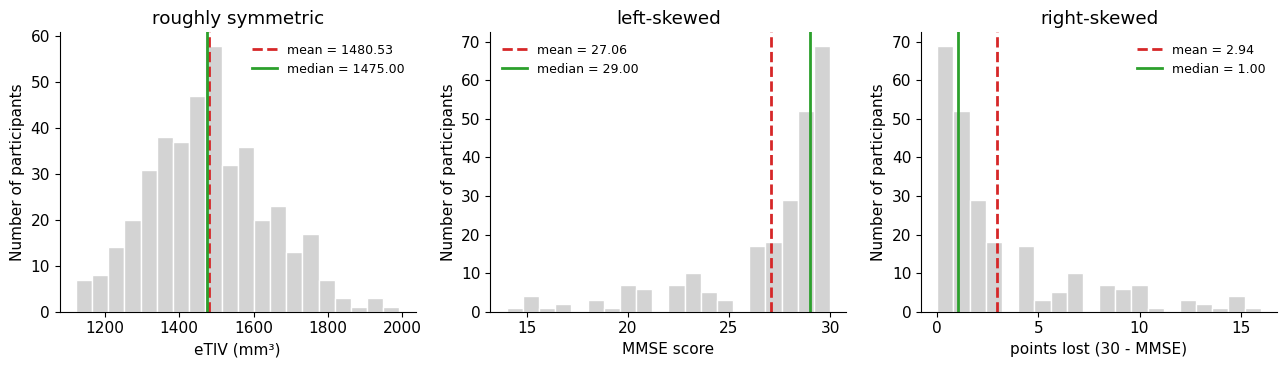

In [9]:
mmse = df["MMSE"].dropna()
examples = [
    (df["eTIV"],  "eTIV (mm³)",        "roughly symmetric"),
    (mmse,        "MMSE score",        "left-skewed"),
    (30 - mmse,   "points lost (30 - MMSE)", "right-skewed"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (x, xlabel, title) in zip(axes, examples):
    ax.hist(x, bins=20, color="lightgray", edgecolor="white")
    ax.axvline(x.mean(),   color="tab:red",   ls="--", lw=2, label=f"mean = {x.mean():.2f}")
    ax.axvline(x.median(), color="tab:green", ls="-",  lw=2, label=f"median = {x.median():.2f}")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of participants")
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

In [10]:
pd.DataFrame({
    "n":        [len(x) for x, _, _ in examples],
    "mean":     [x.mean() for x, _, _ in examples],
    "median":   [x.median() for x, _, _ in examples],
    "skewness": [stats.skew(x) for x, _, _ in examples],
}, index=[t for _, _, t in examples]).round(2)

,n,mean,median,skewness
roughly symmetric,416,1480.53,1475.0,0.3
left-skewed,235,27.06,29.0,-1.6
right-skewed,235,2.94,1.0,1.6


A positive skewness means a right-skewed distribution, a negative one a left-skewed distribution.

**Caution:** mean and median can also agree when *neither* describes the data well. `Age` has a mean and a median in the middle of the range, but there are hardly any participants there: the sample consists of two clusters, young adults and older adults.

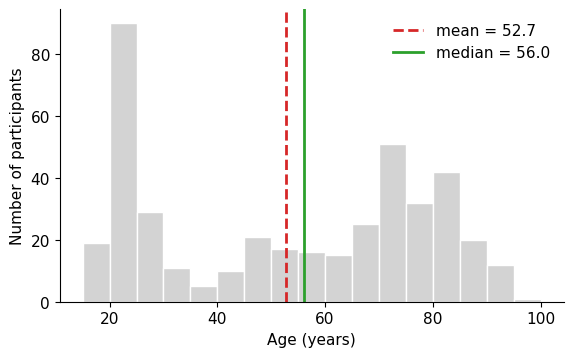

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(df["Age"], bins=np.arange(15, 101, 5), color="lightgray", edgecolor="white")
ax.axvline(df["Age"].mean(),   color="tab:red",   ls="--", lw=2, label=f"mean = {df['Age'].mean():.1f}")
ax.axvline(df["Age"].median(), color="tab:green", ls="-",  lw=2, label=f"median = {df['Age'].median():.1f}")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of participants")
ax.legend(frameon=False)
plt.show()

## 1.5 When to use mode, median and mean

Each parameter requires a different minimum scale of measurement:

| Scale | mode | median | mean | OASIS examples |
|---|---|---|---|---|
| nominal | yes | no | no | `M/F`, `Hand` |
| ordinal | yes | yes | no | `Educ`, `SES`, `CDR` |
| equal-interval | yes | yes | yes | `Age`, `eTIV`, `nWBV` (and `MMSE`) |

**Always use the mean for equal-interval data? No!** Consider **outliers**. A few participants with low `MMSE` scores pull the **mean** down, while the **median** stays close to where most of the participants are.

In [12]:
print(f"MMSE: mean = {mmse.mean():.2f}, median = {mmse.median():.1f}, n = {len(mmse)}")
print(f"share of participants with the maximum score of 30: {100 * (mmse == 30).mean():.0f}%")

MMSE: mean = 27.06, median = 29.0, n = 235
share of participants with the maximum score of 30: 29%


## 1.6 Variance

The **variance** is a measure of dispersion: it quantifies how much every individual value deviates from the mean. It needs at least equal-interval data.

Why the square? Positive and negative deviations from the mean would otherwise cancel each other out.

**Population variance** (the whole population is known, we divide by $N$):

$$\sigma^2 = \frac{1}{N}\sum_{i=1}^{N}(x_i-\mu)^2$$

**Sample variance** (we only know a sample and estimate the population, we divide by $N-1$):

$$s^2 = \frac{1}{N-1}\sum_{i=1}^{N}(x_i-\bar{x})^2$$


**Watch out:** libraries differ in their default! NumPy divides by $N$ (`ddof=0`), pandas divides by $N-1$ (`ddof=1`).

In [13]:
x = df["MMSE"][:10] # taking 10 values as an example
print("np.var(x)           :", round(np.var(x), 2))
print("np.var(x, ddof=1)   :", round(np.var(x, ddof=1), 2))
print("pd.Series(x).var()  :", round(pd.Series(x).var(), 2))

np.var(x)           : 1.2
np.var(x, ddof=1)   : 1.5
pd.Series(x).var()  : 1.5


### Why $N-1$? The sample variance correctly estimates the population variance independent of $N$

Simulation: we pretend that the 416 `eTIV` values *are* the population. We draw many random samples of size $n$ and compute the variance of every sample with both formulas. If a formula estimates the population variance well, its average over many samples should match the true value.

In [14]:
population = df["eTIV"].to_numpy()
true_var = population.var()            # population variance (divide by N)

rows = []
for n in [3, 5, 10, 30, 100]:
    samples = rng.choice(population, size=(10_000, n), replace=True)
    rows.append({
        "n": n,
        "divide by N":     samples.var(axis=1, ddof=0).mean(),
        "divide by N - 1": samples.var(axis=1, ddof=1).mean(),
        "divide by N - 2": samples.var(axis=1, ddof=2).mean(),
    })
ratio = pd.DataFrame(rows).set_index("n")
ratio.round(3)

,divide by N,divide by N - 1,divide by N - 2
n,,,
3,16609.434,24914.151,49828.302
5,19795.292,24744.115,32992.153
10,22746.366,25273.740,28432.957
30,24174.641,25008.249,25901.401
100,24751.032,25001.042,25256.155


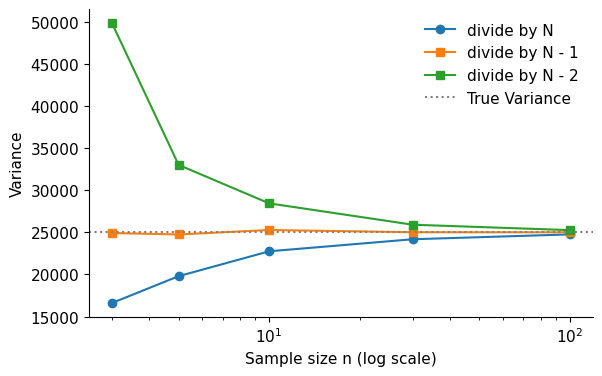

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(ratio.index, ratio["divide by N"], "o-", label="divide by N")
ax.plot(ratio.index, ratio["divide by N - 1"], "s-", label="divide by N - 1")
ax.plot(ratio.index, ratio["divide by N - 2"], "s-", label="divide by N - 2")
ax.axhline(true_var, color="gray", ls=":", label='True Variance')
ax.set_xscale("log")
ax.set_xlabel("Sample size n (log scale)")
ax.set_ylabel("Variance")
ax.legend(frameon=False)
plt.show()

Dividing by $N$ underestimates the variance, and the smaller the sample, the larger the error. Dividing by $N-1$ corrects for this: on average it hits the true value.

## 1.7 Standard deviation

The variance is in **squared units** (mm⁶ for `eTIV`!), which is hard to interpret. The **standard deviation** is its square root, and is back in the original units. It also needs equal-interval data.

$$s = \sqrt{s^2} \qquad\qquad \sigma = \sqrt{\sigma^2}$$

In [16]:
cols = ["Age", "eTIV"]
pd.DataFrame({
    "unit":          ["years", "mm³"],
    "mean":          df[cols].mean(),
    "variance s²":   df[cols].var(),
    "SD's":          df[cols].std(),
}).round(4)

,unit,mean,variance s²,SD's
Age,years,52.7019,629.1158,25.0822
eTIV,mm³,1480.5264,25072.7415,158.3437


## 1.8 Standard error of the mean

The **standard error of the mean (SEM)** quantifies how closely the *sample mean* represents the *population mean*:

$$SEM = \frac{s}{\sqrt{N}}$$

It usually decreases with increasing sample size: the larger the sample, the better we estimate the "true" population value.

In [17]:
x = df["eTIV"]
print(f"eTIV: s = {x.std():.4f}, N = {len(x)}, SEM = s / sqrt(N) = {x.std() / np.sqrt(len(x)):.5f}")
print(f"pandas .sem():                           {x.sem():.5f}")

eTIV: s = 158.3437, N = 416, SEM = s / sqrt(N) = 7.76344
pandas .sem():                           7.76344


Effect of sample size: we draw random subsamples of different sizes from `nWBV` and compute their SEM.

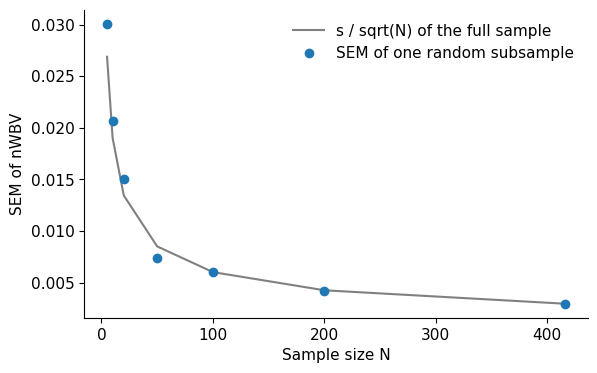

In [18]:
values = df["nWBV"].to_numpy()
sizes = [5, 10, 20, 50, 100, 200, 416]

observed = [rng.choice(values, size=n, replace=False).std(ddof=1) / np.sqrt(n) for n in sizes]
expected = values.std(ddof=1) / np.sqrt(sizes)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(sizes, expected, "-", color="gray", label="s / sqrt(N) of the full sample")
ax.plot(sizes, observed, "o", label="SEM of one random subsample")
ax.set_xlabel("Sample size N")
ax.set_ylabel("SEM of nWBV")
ax.legend(frameon=False)
plt.show()

SEM per nWBV, which we will need again for the error bars in the bar plot. The numbers show the difference between the three parameters: **SD** describes the spread of the *participants*, **SEM** the precision of the *mean*.

In [19]:
cdr_stats = df.groupby("CDR")["nWBV"].agg(n="count", mean="mean", SD="std", SEM="sem")
cdr_stats.round(4)

,n,mean,SD,SEM
CDR,,,,
0.0,135,0.7692,0.0459,0.0039
0.5,70,0.7294,0.0353,0.0042
1.0,28,0.7062,0.0312,0.0059
2.0,2,0.6840,0.0269,0.0190


Note the group `CDR = 2` with only two participants: its SD and SEM are not meaningful.

## 1.9 Take-home messages

- **Mean and variance** are the two main parameters that describe a distribution (technically also its shape).
- The **variance** is the "primal" value, the **standard deviation** is the interpretable one (same units as the data).
- Variance and SD describe the dispersion of the *observations*. The **SEM** is attached to a statistical parameter (usually the mean) and describes how well that parameter represents the population value.
- The SEM divides by $\sqrt{N}$ because the SD is the square root of an already squared quantity: the units have to match.

---
# 2. Diagrams

## 2.1 Bar plots

Bar plots display **frequencies or percentages of discrete variables**. Example: how many participants are in each dementia rating (`CDR`)?

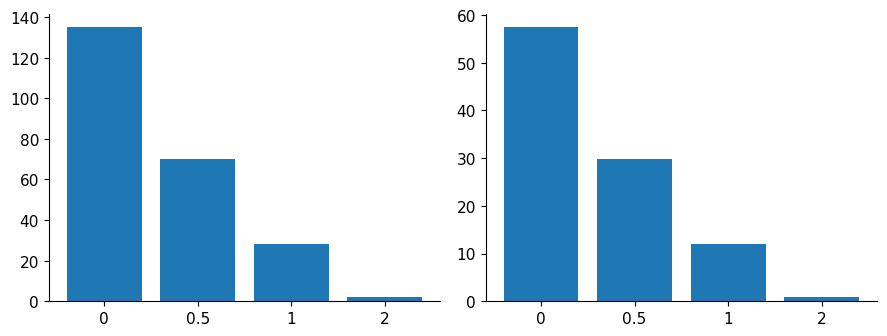

In [20]:
cdr_counts = df["CDR"].value_counts().sort_index()
cdr_pct = 100 * cdr_counts / cdr_counts.sum()
cdr_x = [f"{c:g}" for c in cdr_counts.index]     # 0.0 -> "0", 0.5 -> "0.5"

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].bar(cdr_x, cdr_counts.values)
axes[1].bar(cdr_x, cdr_pct.values)
plt.tight_layout()
plt.show()

Without labels, nobody knows what this shows: **label the axes!**

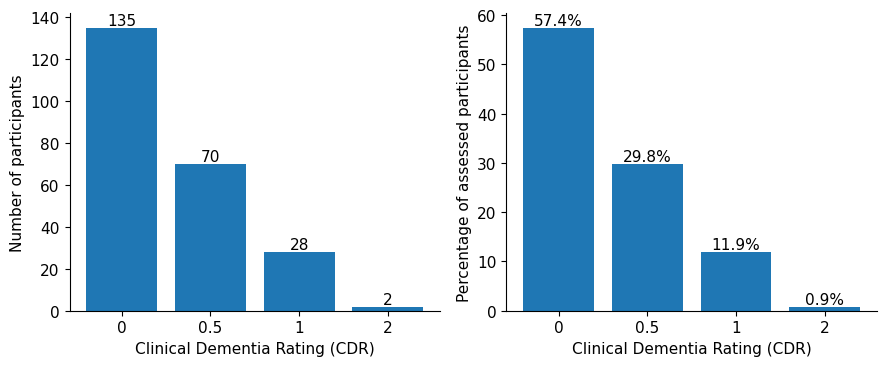

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))

bars = axes[0].bar(cdr_x, cdr_counts.values, color="tab:blue")
axes[0].bar_label(bars)
axes[0].set_ylabel("Number of participants")

bars = axes[1].bar(cdr_x, cdr_pct.values, color="tab:blue")
axes[1].bar_label(bars, fmt="%.1f%%")
axes[1].set_ylabel("Percentage of assessed participants")

for ax in axes:
    ax.set_xlabel("Clinical Dementia Rating (CDR)")
plt.tight_layout()
plt.show()

Bar plots are also used for **means**. Then we need **error bars** that show the uncertainty of the mean. Here: mean `nWBV` per `CDR` group, with the SEM as error bars (from section 1.8).

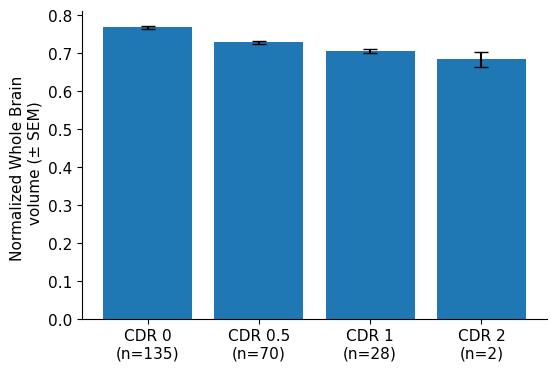

In [22]:
levels = [0.0, 0.5, 1.0, 2.0]
xlabels = [f"CDR {c:g}\n(n={int(cdr_stats.loc[c, 'n'])})" for c in levels]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(4), cdr_stats.loc[levels, "mean"], yerr=cdr_stats.loc[levels, "SEM"],
       capsize=5, color="tab:blue")
ax.set_xticks(range(4), xlabels)
ax.set_ylabel("Normalized Whole Brain \n volume (± SEM)")
plt.show()

**Wait... does a bar plot really make sense for continuous data?** A bar plot reduces each group to one number. Different distributions can give the same bar. Compare the same data as (1) bars with error bars, (2) bars with the individual participants, (3) a boxplot:

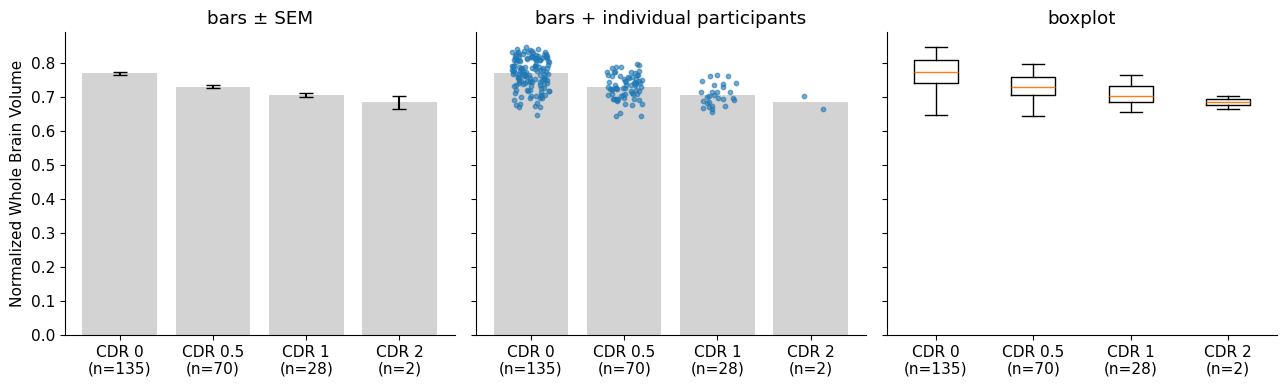

In [23]:
groups = [df.loc[df["CDR"] == c, "nWBV"].to_numpy() for c in levels]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

# (1) bars + SEM
axes[0].bar(range(4), [g.mean() for g in groups], yerr=[stats.sem(g) for g in groups],
            capsize=5, color="lightgray")
axes[0].set_title("bars ± SEM")

# (2) bars + raw data
axes[1].bar(range(4), [g.mean() for g in groups], color="lightgray")
for i, g in enumerate(groups):
    axes[1].scatter(i + rng.uniform(-0.2, 0.2, len(g)), g, s=10, color="tab:blue", alpha=0.6)
axes[1].set_title("bars + individual participants")

# (3) boxplot
axes[2].boxplot(groups)
axes[2].set_xticks(range(1, 5))
axes[2].set_title("boxplot")

for ax in axes:
    if ax is not axes[2]:
        ax.set_xticks(range(4))
    ax.set_xticklabels(xlabels)
axes[0].set_ylabel("Normalized Whole Brain Volume")
plt.tight_layout()
plt.show()

The bars hide the distribution, the group sizes (note again `CDR 2`!) and any outliers. For continuous data, prefer plots that show the distribution itself: histograms, boxplots, or raincloud plots (see below).

## 2.2 Histograms

A histogram is similar to a bar plot, but for **continuous values**. It plots the distribution in bins. **You** decide how fine-grained the representation is by choosing the bin size, so the same data can look very different:

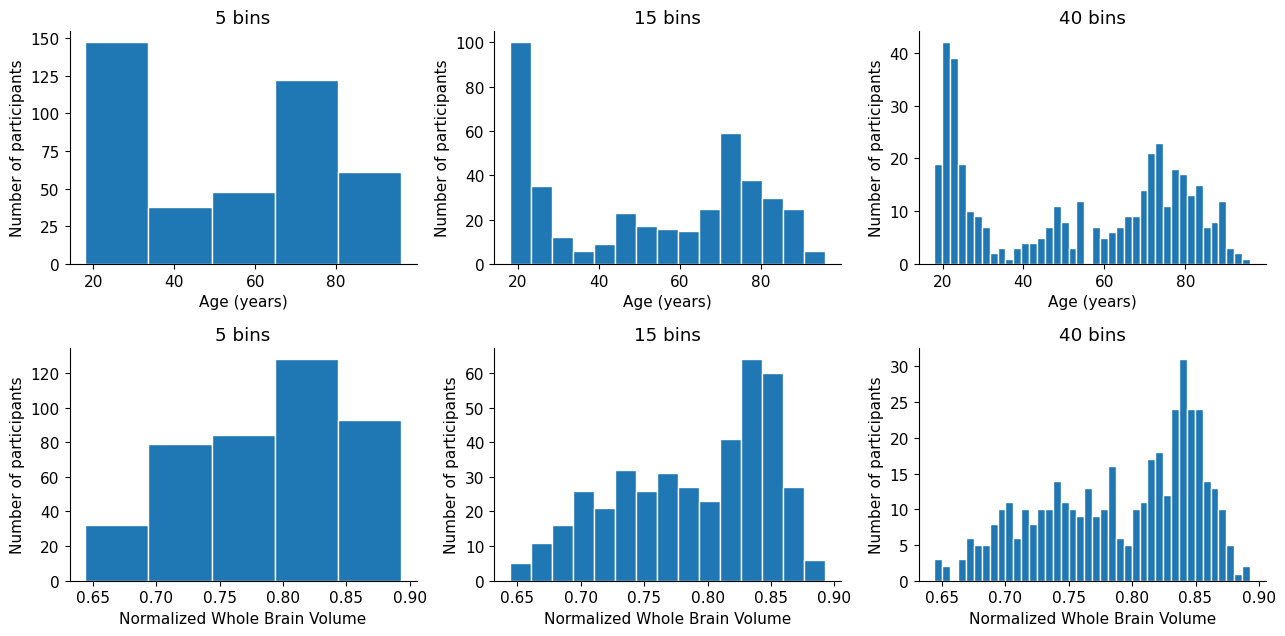

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for row, (col, xlabel) in enumerate([("Age", "Age (years)"), ("nWBV", "Normalized Whole Brain Volume")]):
    for ax, bins in zip(axes[row], [5, 15, 40]):
        ax.hist(df[col], bins=bins, color="tab:blue", edgecolor="white")
        ax.set_title(f"{bins} bins")
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Number of participants")
plt.tight_layout()
plt.show()

With 5 bins the picture is very coarse: the sharp peak in the early twenties disappears inside the first bar. With 15 bins the peak, the dip in between and the cluster of older participants are all visible. With 40 bins the plot becomes jagged. A good bin size shows the overall shape without too much noise.

## 2.3 Boxplots

A boxplot shows several parameters at once:
- minimum and maximum value
- the quarters of the data (including the median)
- outliers

The distance between the 1st and 3rd quartile is the **interquartile range (IQR)**. Values far away from the box are flagged as outliers:
- **strict criterion:** more than 1.5 × IQR below Q1 / above Q3
- **liberal criterion:** more than 3 × IQR below Q1 / above Q3

**Computing it by hand** for `MMSE`:

In [25]:
mmse = df['MMSE'].dropna()
q1, med, q3 = mmse.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1

print(pd.Series({"min": mmse.min(), "Q1": q1, "median": med, "Q3": q3, "max": mmse.max(),
                 "range": mmse.max() - mmse.min(), "IQR": iqr}).to_string())

for name, k in [("strict  (1.5 x IQR)", 1.5), ("liberal (3 x IQR)  ", 3.0)]:
    lower, upper = q1 - k * iqr, q3 + k * iqr
    n_out = ((mmse < lower) | (mmse > upper)).sum()
    print(f"\n{name}: fences at {lower:.1f} and {upper:.1f} -> {n_out} outliers")

min       14.0
Q1        26.0
median    29.0
Q3        30.0
max       30.0
range     16.0
IQR        4.0

strict  (1.5 x IQR): fences at 20.0 and 36.0 -> 12 outliers

liberal (3 x IQR)  : fences at 14.0 and 42.0 -> 0 outliers


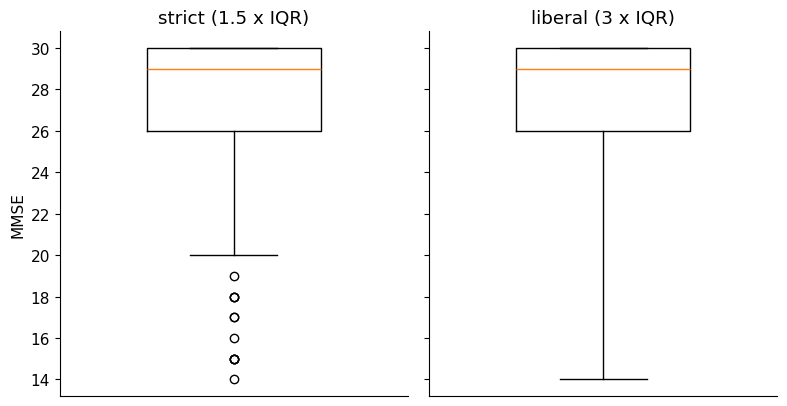

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), sharey=True)
for ax, (k, title) in zip(axes, [(1.5, "strict (1.5 x IQR)"), (3.0, "liberal (3 x IQR)")]):
    ax.boxplot(mmse, whis=k, widths=0.5)
    ax.set_title(title)
    ax.set_xticks([])
axes[0].set_ylabel("MMSE")
plt.tight_layout()
plt.show()

The same data has 12 outliers under the strict criterion and none under the liberal one: "outlier" depends on the rule you choose. Report which one you used.

**Make your own boxplot.** Slide exercise: draw a boxplot from these summary values: range = 60, IQR = 23, median = 10, Q1 = 7, Q3 = 30, max = 60, min = 0. Are there any outliers?

strict fences:  -27.5 to 64.5
liberal fences: -62.0 to 99.0
min and max inside the fences? -> True


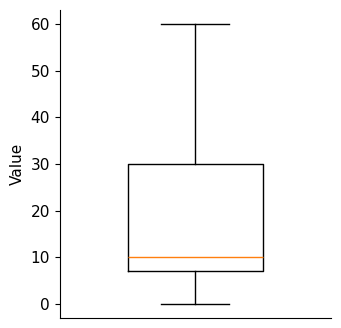

In [27]:
q1, q3, lo, hi = 7, 30, 0, 60
iqr = q3 - q1
print(f"strict fences:  {q1 - 1.5 * iqr:.1f} to {q3 + 1.5 * iqr:.1f}")
print(f"liberal fences: {q1 - 3.0 * iqr:.1f} to {q3 + 3.0 * iqr:.1f}")
print("min and max inside the fences? ->", q1 - 1.5 * iqr <= lo and hi <= q3 + 1.5 * iqr)

fig, ax = plt.subplots(figsize=(3.5, 4))
ax.bxp([{"med": 10, "q1": q1, "q3": q3, "whislo": lo, "whishi": hi, "fliers": []}], widths=0.5)
ax.set_xticks([])
ax.set_ylabel("Value")
plt.show()

Both the minimum (0) and the maximum (60) lie inside the fences, so there are **no outliers**, and the whiskers simply reach to the minimum and maximum.

**Boxplots for groups:** `eTIV` by dementia rating.

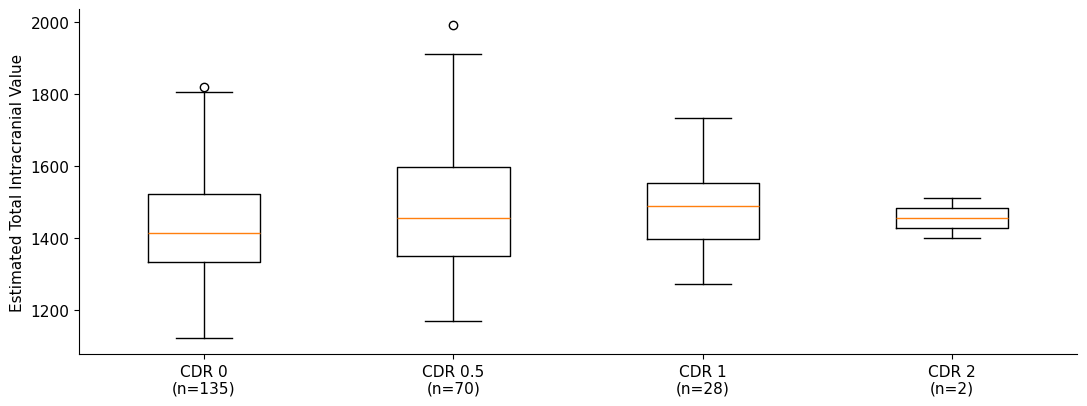

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(11, 4.2))
data = [df.loc[df["CDR"] == c, "eTIV"].to_numpy() for c in levels]
ax.boxplot(data)
ax.set_xticks(range(1, 5), [f"CDR {c:g}\n(n={len(d)})" for c, d in zip(levels, data)])
ax.set_ylabel("Estimated Total Intracranial Value")
plt.tight_layout()
plt.show()

## 2.4 Scatterplots

Scatterplots show the **relationship between two continuous, equal-interval variables**. Every point is one participant, and its coordinates are the scores on the two variables.

Brain volume shrinks with age, and more strongly in dementia:

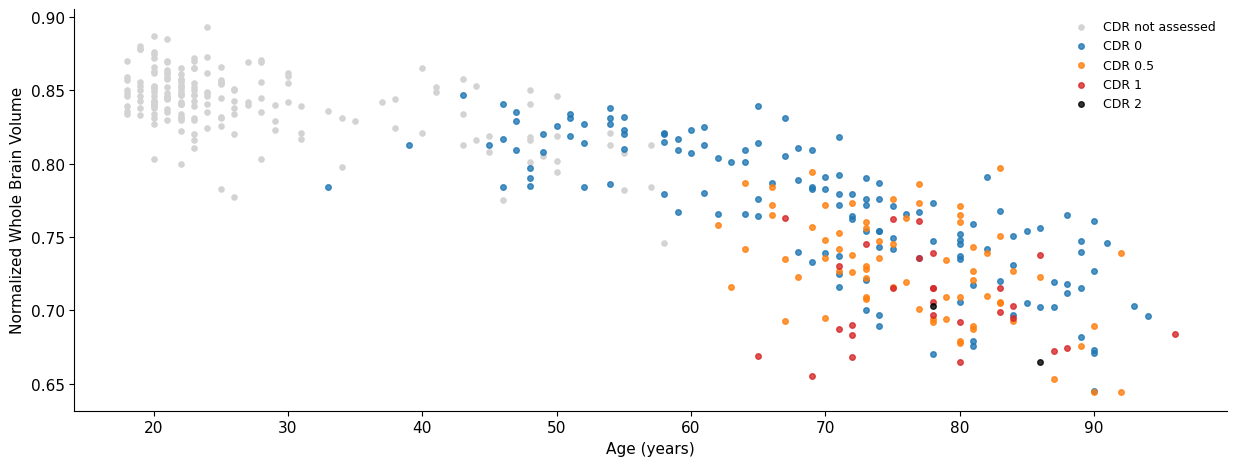

In [29]:
colors = {0.0: "tab:blue", 0.5: "tab:orange", 1.0: "tab:red", 2.0: "black"}

fig, ax = plt.subplots(1, 1, figsize=(12.5, 4.8))

# left: Age vs. nWBV, everybody
unassessed = df[df["CDR"].isna()]
ax.scatter(unassessed["Age"], unassessed["nWBV"], s=14, color="lightgray", label="CDR not assessed")
for c in levels:
    sub = df[df["CDR"] == c]
    ax.scatter(sub["Age"], sub["nWBV"], s=16, color=colors[c], alpha=0.8, label=f"CDR {c:g}")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Normalized Whole Brain Volume")
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

`nWBV` decreases with `Age`, and the participants with dementia are among the older ones with lower volumes. How to quantify such relationships is the topic of the next sessions (correlation and regression).

## 2.5 Raincloud plots

Raincloud plots (Allen et al., 2021) combine three views of the same data, so nothing is hidden:
- the **cloud**: the shape of the distribution (a smoothed density estimate)
- the **rain**: every individual data point
- the **box**: the summary (median and quartiles)

We draw one for `nWBV` by dementia rating (`CDR 2` is left out, because two participants are too few for a distribution).

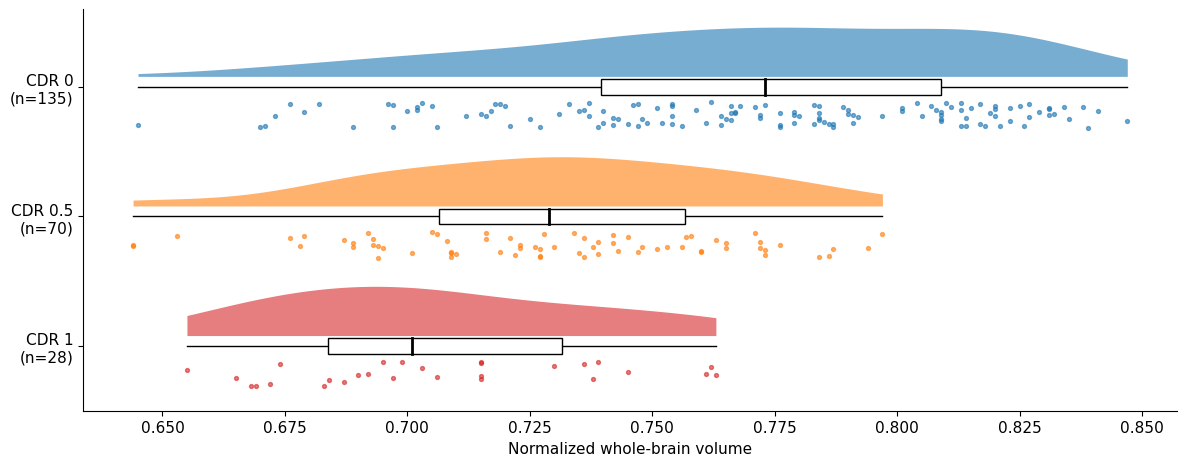

In [30]:
from matplotlib.patches import Rectangle

def raincloud(ax, groups, labels, colors, cloud_height=0.38):
    n = len(groups)
    for i, (g, color) in enumerate(zip(groups, colors)):
        g = np.asarray(g, dtype=float)
        y = n - 1 - i                      # first group at the top

        # cloud: smoothed density, drawn above the box, limited to the observed range
        grid = np.linspace(g.min(), g.max(), 200)
        dens = stats.gaussian_kde(g)(grid)
        dens = dens / dens.max() * cloud_height
        ax.fill_between(grid, y + 0.08, y + 0.08 + dens, color=color, alpha=0.6, lw=0)

        # box: median, quartiles and whiskers (strict 1.5 x IQR criterion), in the middle
        q1, med, q3 = np.percentile(g, [25, 50, 75])
        iqr = q3 - q1
        low, high = g[g >= q1 - 1.5 * iqr].min(), g[g <= q3 + 1.5 * iqr].max()
        ax.plot([low, q1], [y, y], color="black", lw=1, zorder=2)
        ax.plot([q3, high], [y, y], color="black", lw=1, zorder=2)
        ax.add_patch(Rectangle((q1, y - 0.06), q3 - q1, 0.12, facecolor="white",
                               edgecolor="black", lw=1, zorder=3))
        ax.plot([med, med], [y - 0.06, y + 0.06], color="black", lw=2, zorder=4)

        # rain: every single participant, jittered below the box
        ax.scatter(g, y - 0.12 - rng.uniform(0, 0.2, len(g)), s=8, color=color, alpha=0.6)

    ax.set_yticks(range(n), labels[::-1])
    ax.set_ylim(-0.5, n - 1 + 0.6)

levels3 = [0.0, 0.5, 1.0]
labels3 = [f"CDR {c:g}\n(n={(df['CDR'] == c).sum()})" for c in levels3]
cols3 = [colors[c] for c in levels3]

fig, ax = plt.subplots(1, 1, figsize=(12, 4.8))

raincloud(ax, [df.loc[df["CDR"] == c, "nWBV"] for c in levels3], labels3, cols3)
ax.set_xlabel("Normalized whole-brain volume")
plt.tight_layout()
plt.show()

---
## Summary

| Question | Parameter / plot |
|---|---|
| most frequent value (any scale) | mode, frequency table, bar plot |
| middle of the data (ordinal or higher) | median, boxplot |
| average (equal-interval) | mean, sensitive to outliers and skew |
| spread of the observations | variance, standard deviation |
| precision of the mean | standard error of the mean |
| shape of a continuous distribution | histogram, boxplot, raincloud plot |
| relationship of two continuous variables | scatterplot |

**Sources**
- Marcus, D. S. et al. (2007). Open Access Series of Imaging Studies (OASIS): Cross-sectional MRI data in young, middle aged, nondemented, and demented older adults. *Journal of Cognitive Neuroscience, 19*, 1498-1507.
- Allen, M., Poggiali, D., Whitaker, K. et al. (2021). Raincloud plots: a multi-platform tool for robust data visualization. *Wellcome Open Research, 4*:63.